# 04 – Feature importance, sensitivity and residual analysis
**Goal:** find out *which inputs the model relies on*, how accuracy changes as inputs are added or removed,
and *where* the model's errors are largest. All results here use the held-out test vehicles.

In [1]:
import sys; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from ev_energy import (load_data, clean_data, split_by_vehicle, evaluate, fit_and_time,
                       grouped_permutation_importance, error_by_group,
                       TARGET, TRIP_FEATURES, ELECTRICAL_FEATURES)

SEED = 42
df = clean_data(load_data("../data/raw/ev_trip_energy.csv"))
train, test = split_by_vehicle(df, test_size=0.2, seed=SEED)
FEATURES = TRIP_FEATURES + ELECTRICAL_FEATURES

# Settings chosen by cross-validation in notebook 03 (fixed here so we do not re-run the search)
BEST = dict(n_estimators=200, max_depth=12, min_samples_leaf=5, random_state=SEED, n_jobs=-1)
rf = RandomForestRegressor(**BEST).fit(train[FEATURES], train[TARGET])
pred = rf.predict(test[FEATURES])
print({k: round(v, 3) for k, v in evaluate(test[TARGET], pred).items()})

{'MAE': 0.74, 'RMSE': 1.105, 'R2': 0.866}


## 1. Feature importance
**Permutation importance:** shuffle one input (or a group of related inputs) in the test set and see how much the error rises.
A big rise means the model relies on that input. The two temperature columns are almost identical (correlation 0.99), so they are shuffled together as one group;
otherwise each would look unimportant because the other could stand in for it.
For comparison we also show the forest's built-in importance, which is based on how much each input reduces error inside the trees.

,mae_increase_mean,mae_increase_std
group,,
distance,2.202,0.021
hour of day,0.069,0.003
current,0.062,0.004
battery temperature,0.038,0.004
voltage,0.017,0.003
duration,0.011,0.002
avg speed,0.007,0.001
weekday,0.000,0.001


,built-in importance
distance_km,0.904
hour,0.029
current_a,0.020
voltage_v,0.014
temp_min_c,0.010
duration_min,0.007
avg_speed_kmh,0.007
temp_max_c,0.006
weekday,0.003


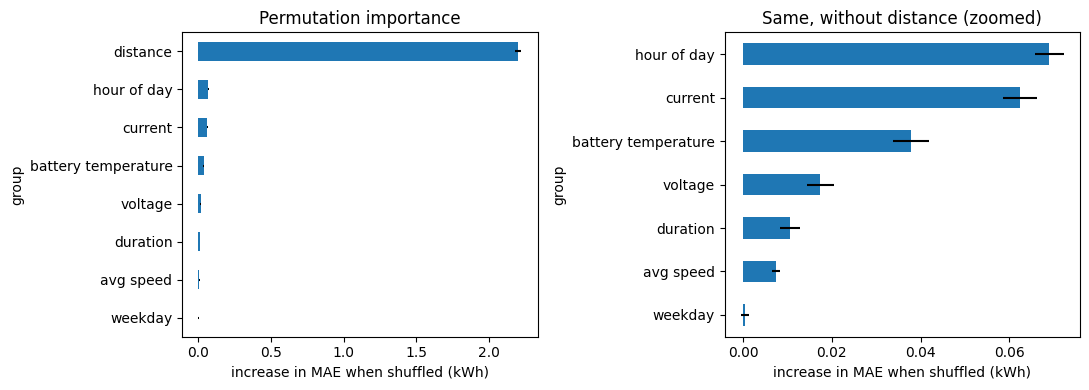

In [2]:
groups = {"distance": ["distance_km"], "duration": ["duration_min"], "avg speed": ["avg_speed_kmh"],
          "hour of day": ["hour"], "weekday": ["weekday"],
          "battery temperature": ["temp_max_c", "temp_min_c"],
          "current": ["current_a"], "voltage": ["voltage_v"]}
imp = grouped_permutation_importance(rf, test[FEATURES], test[TARGET], groups, n_repeats=10, seed=SEED)
built_in = pd.Series(rf.feature_importances_, index=FEATURES).sort_values(ascending=False)
display(imp.round(3))
display(built_in.round(3).to_frame("built-in importance"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
imp["mae_increase_mean"].iloc[::-1].plot.barh(ax=ax[0], xerr=imp["mae_increase_std"].iloc[::-1])
ax[0].set(xlabel="increase in MAE when shuffled (kWh)", title="Permutation importance")
imp["mae_increase_mean"].drop("distance").iloc[::-1].plot.barh(ax=ax[1], xerr=imp["mae_increase_std"].drop("distance").iloc[::-1])
ax[1].set(xlabel="increase in MAE when shuffled (kWh)", title="Same, without distance (zoomed)")
plt.tight_layout(); plt.savefig("../figures/feature_importance.png", dpi=150); plt.show()

**Interpretation:** Distance dominates. Shuffling it raises the test error by about 2.2 kWh, while every other input raises it by less than 0.07 kWh, and the forest's built-in importance agrees (distance about 0.90 of the total). This matches the earlier finding that a fixed kWh-per-km rate already explains most of the variation.
Among the smaller effects, hour of day (0.069 kWh), current (0.062) and battery temperature (0.038) matter most, followed by voltage (0.017). Duration, average speed and weekday add almost nothing: duration and speed are derived from distance and mostly repeat what the model already knows, and day of the week has no measurable effect.
Caution: permutation importance measures how much *this model* leans on an input, not a physical cause. Correlated inputs can share or hide importance, which is why temperature was grouped. Hour of day may be standing in for conditions we did not record (traffic, driver, trip purpose).

## 2. Sensitivity: how does accuracy change as inputs are added?
Retrain the forest with progressively more inputs and score each on the same test vehicles. This also answers the project question about trip characteristics alone versus trip + electrical measurements.

In [3]:
steps = {
    "distance only":                              ["distance_km"],
    "+ duration, average speed":                  ["distance_km", "duration_min", "avg_speed_kmh"],
    "+ hour of day, weekday":                     ["distance_km", "duration_min", "avg_speed_kmh", "hour", "weekday"],
    "+ battery temperature (= all trip features)": TRIP_FEATURES,
    "+ current":                                  TRIP_FEATURES + ["current_a"],
    "+ voltage (= all features)":                 FEATURES,
}
rows = []
for name, feats in steps.items():
    _, m = fit_and_time(RandomForestRegressor(**BEST), train, test, feats)
    rows.append({"inputs": name, "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"]})
sens = pd.DataFrame(rows).set_index("inputs").round(3)
sens.to_csv("../docs/results_04_sensitivity.csv")
sens

,MAE,RMSE,R2
inputs,,,
distance only,0.855,1.272,0.822
"+ duration, average speed",0.880,1.297,0.815
"+ hour of day, weekday",0.829,1.209,0.839
+ battery temperature (= all trip features),0.784,1.166,0.850
+ current,0.745,1.116,0.863
+ voltage (= all features),0.740,1.105,0.866


**Interpretation:** Distance alone gives MAE 0.855 kWh and R² 0.82, about the same as the fixed-rate baseline (0.867 kWh), so a forest with only distance has learned little more than a constant kWh-per-km rate.
Adding duration and average speed does not help (MAE rises slightly to 0.880), because they are derived from distance and add no new information. The gains come from other sources: time of day and weekday (to 0.830), battery temperature (0.784), and then current (0.745) and voltage (0.740).
Trip-only features (all but current and voltage) reach MAE 0.784 and R² 0.851. Adding the electrical measurements gives 0.740 and 0.866. So electrical data improves accuracy by about 6%, mostly through current, but it is measured during the trip and would not be available before departure.
Caveat: this uses a single split of 10 test vehicles, and differences of 0.02 to 0.04 kWh are about as large as the split-to-split variation seen in notebook 03, so treat the small steps as suggestive.

## 3. Residual analysis: where are the errors?
Residual = actual − predicted, so a **positive** residual means the model **under**-predicted.
We summarise the number of trips, the mean residual (bias) and the MAE inside bands of trip conditions.
(Bands of *actual* energy exaggerate the bias because they select on the outcome, so use them with care; bands of inputs such as distance, hour and temperature are more reliable.)

overall mean residual: 0.136 kWh

actual energy (kWh)


,trips,mean_residual,MAE
energy_kwh,,,
"(0, 2]",479,-0.202,0.289
"(2, 4]",772,-0.038,0.519
"(4, 8]",661,0.185,0.900
"(8, 25]",280,1.077,1.745



distance (km)


,trips,mean_residual,MAE
distance_km,,,
"(0, 10]",693,0.141,0.418
"(10, 20]",731,0.085,0.658
"(20, 40]",573,0.198,0.996
"(40, 100]",195,0.127,1.441



hour of day


,trips,mean_residual,MAE
hour,,,
0-6 night,175,0.263,1.323
6-10 morning,357,0.217,0.702
10-16 midday,859,0.027,0.619
16-20 evening,556,0.162,0.729
20-24 late,245,0.249,0.831



max cell temperature (C)


,trips,mean_residual,MAE
temp_max_c,,,
<10,145,0.374,0.664
10-20,1136,0.212,0.720
20-30,876,-0.007,0.771
>30,35,0.263,0.932


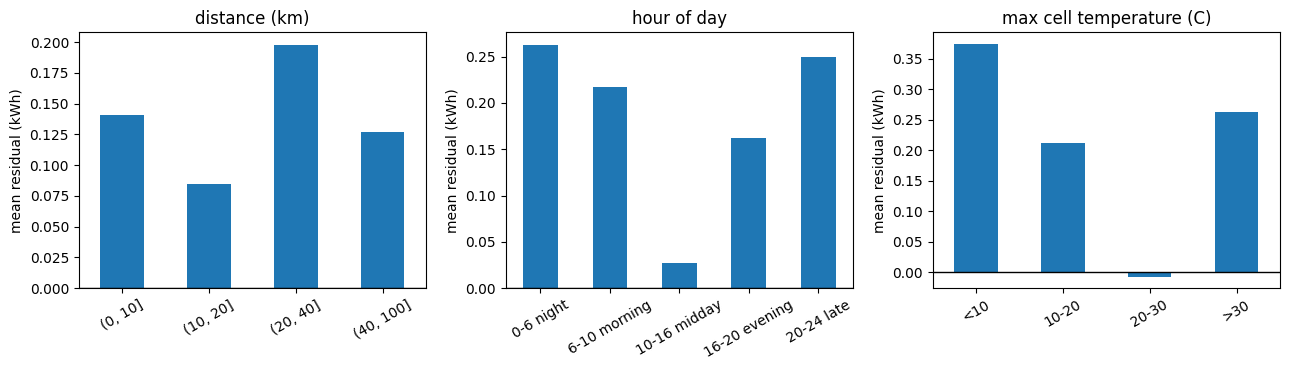

In [4]:
t = test.assign(pred=pred, resid=test[TARGET] - pred)
bands = {
    "actual energy (kWh)": pd.cut(t[TARGET], [0, 2, 4, 8, 25]),
    "distance (km)": pd.cut(t.distance_km, [0, 10, 20, 40, 100]),
    "hour of day": pd.cut(t.hour, [-1, 6, 10, 16, 20, 24],
                          labels=["0-6 night", "6-10 morning", "10-16 midday", "16-20 evening", "20-24 late"]),
    "max cell temperature (C)": pd.cut(t.temp_max_c, [-5, 10, 20, 30, 40], labels=["<10", "10-20", "20-30", ">30"]),
}
print("overall mean residual:", round(t.resid.mean(), 3), "kWh")
tables = {}
for name, b in bands.items():
    tables[name] = error_by_group(t[TARGET], t.pred, b).round(3)
    print("\n" + name); display(tables[name])

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, key in zip(ax, ["distance (km)", "hour of day", "max cell temperature (C)"]):
    tables[key]["mean_residual"].plot.bar(ax=a, rot=30)
    a.axhline(0, color="k", lw=1); a.set(title=key, ylabel="mean residual (kWh)", xlabel="")
plt.tight_layout(); plt.savefig("../figures/residuals_by_condition.png", dpi=150); plt.show()

**Interpretation:** Overall the model under-predicts slightly: the mean residual is +0.14 kWh. Error size grows with trip length: MAE rises from 0.42 kWh for trips under 10 km to 1.44 kWh for trips over 40 km. This is the fan shape in the residual plot, and it means estimates for long trips are the least reliable.
The bias is small but positive in every distance band (+0.08 to +0.20 kWh), so the tendency to under-predict is general, not limited to long trips. In the bands of actual energy the bias looks larger (about +1.1 kWh for trips over 8 kWh and −0.2 kWh for trips under 2 kWh), but this is partly an artefact of selecting on the outcome: a model that averages similar trips will always over-predict the lowest values and under-predict the highest.
Errors are largest for night trips (0–6 h, MAE 1.32 kWh against 0.62–0.83 kWh at other times), but there are only 175 of them, and we have not checked whether they are also longer, so we cannot say the time of day itself is the cause. Cold trips (max cell temperature under 10 °C) are under-predicted by about 0.37 kWh. A possible reason is extra energy for heating and lower battery efficiency in the cold, but this dataset cannot confirm it. The hottest band (over 30 °C) has only 35 trips, so it is not reliable.
Under-prediction is the unsafe direction for range estimation, because the car could use more energy than the model says.

## 4. Unseen vehicles: do errors differ between cars?
The test set contains 10 vehicles the model has never seen. Look at the error for each one.

In [5]:
per_vehicle = (t.groupby("vehicle_id")
                 .agg(trips=("resid", "size"), MAE=("resid", lambda r: r.abs().mean()), mean_residual=("resid", "mean"))
                 .round(3).sort_values("MAE"))
per_vehicle.to_csv("../docs/results_04_per_vehicle.csv")
display(per_vehicle)
print("MAE range across test vehicles:", per_vehicle.MAE.min().round(3), "to", per_vehicle.MAE.max().round(3))

,trips,MAE,mean_residual
vehicle_id,,,
40,276,0.628,-0.469
46,172,0.647,0.194
33,231,0.684,0.092
20,280,0.719,0.059
49,143,0.723,0.101
27,204,0.734,0.200
18,268,0.739,0.310
31,206,0.812,0.254
26,183,0.819,0.350


MAE range across test vehicles: 0.628 to 0.917


**Interpretation:** The error varies moderately between the 10 unseen vehicles: MAE ranges from 0.63 to 0.92 kWh. The bias also differs by car: one vehicle is over-predicted by 0.47 kWh on average while another is under-predicted by 0.44 kWh. So the model transfers to new vehicles reasonably well but not uniformly. Differences between vehicles (driver behaviour, battery age, routes, climate use) are not in the inputs, so each car has an offset the model cannot see.
Limitation: with only 10 test vehicles we cannot say how well this generalises to the whole fleet. For a firmer estimate you could repeat the vehicle split with several seeds, as in notebook 03.

## 5. Summary
- Distance explains most of the variation; the extra inputs bring modest gains (about 6% lower MAE from trip-only to trip + electrical).
- The model is least reliable for long and high-energy trips, and it tends to under-predict slightly.
- Errors differ between cars, which limits generalisation to unseen vehicles.


